In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import time


from utils_ML import score_dataset
from utils_preproces import ols_fit, y_distribution_plot, corr_heatmap_plot, make_mi_scores, preprocess_data

from sklearn.ensemble import RandomForestRegressor, VotingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor, plot_importance
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold

from scikeras.wrappers import KerasRegressor

from sklearn.metrics import mean_absolute_error

In [80]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [81]:
# Fix random state
random_state = 42

In [82]:
harps = pd.read_csv('harps_sample.csv')
apogee = pd.read_csv('apogee_sample.csv')
galah = pd.read_csv('galah_sample.csv')
gr8 = pd.read_csv('gr8_not_in_harps_sample.csv')

print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')
print (f'gr8 contains {len(gr8)} stars')

harps contains 798 stars
apogee contains 108526 stars
galah contains 116050 stars
gr8 contains 1430 stars


In [83]:
apogee = apogee[apogee.parallax >1]
print (len(apogee))
galah = galah[galah.parallax > 2]
print (len(galah))


28385
45103


# Here we focus on getting Fe from no abundance

In [84]:
columns_for_Fe = ['radial_velocity', 'V_lsr',  'U_lsr',  'W_lsr', 'P_gal', # 'parallax',  #'pmra', 'pmdec', #'ra', 'dec',
                'fe_h', ]

apogee = apogee[columns_for_Fe]
harps = harps[columns_for_Fe]
galah = galah[columns_for_Fe]
gr8 = gr8[columns_for_Fe]

In [85]:
def fit_trasform(X):
    X['VW_lsr'] = np.sqrt(X['V_lsr']**2 + X['W_lsr']**2)
    X['UW_lsr'] = np.sqrt(X['U_lsr']**2 + X['W_lsr']**2)
    X['UV_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2)
    X['UVW_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2 + X['W_lsr']**2)
    epsilon = 1e-6
    #log features
    #X['Log_RV'] = np.log(X['RV'] + np.abs(X['RV'].min()))
    X['Log_U_lsr'] = np.log(X['U_lsr'] + np.abs(X['U_lsr'].min()) + epsilon)
    X['Log_V_lsr'] = np.log(X['V_lsr'] + np.abs(X['V_lsr'].min()) + epsilon)
    X['Log_W_lsr'] = np.log(X['W_lsr'] + np.abs(X['W_lsr'].min()) + epsilon)
    X['Log_UW_lsr'] = np.log(X['UW_lsr'])
    X['Log_UVW_lsr'] = np.log(X['UVW_lsr'])

    return X

#apogee = fit_trasform(apogee)
#harps = fit_trasform(harps)
#galah = fit_trasform(galah)
#gr8 = fit_trasform(gr8)

### Identifying and exluding null values

In [86]:
apogee.isnull().sum() # 196 null value for P_gal
apogee.dropna(inplace = True)

In [87]:
galah.isnull().sum() # 1 null value for P_gal
galah.dropna(inplace = True)

In [88]:
#gr8.isnull().sum() # No null values

In [89]:
#harps.isnull().sum() # No null values

### Spliting data into Trianing and Testing sets

In [90]:
# Split APOGEE
apogee_train_full, apogee_test = train_test_split(apogee, test_size=0.1, random_state=random_state)
X_apogee_train = apogee_train_full.drop(columns=['fe_h'])
y_apogee_train = apogee_train_full['fe_h']

X_apogee_test = apogee_test.drop(columns=['fe_h'])
y_apogee_test = apogee_test['fe_h']

# Split GALAH
galah_train_full, galah_test = train_test_split(galah, test_size=0.3, random_state=random_state)
X_galah_train = galah_train_full.drop(columns=['fe_h'])
y_galah_train = galah_train_full['fe_h']

X_galah_test = galah_test.drop(columns=['fe_h'])
y_galah_test = galah_test['fe_h']

# Gr8 no split
X_gr8 = gr8.drop(columns=['fe_h'])
y_gr8 = gr8['fe_h']

# HARPS — no split
X_harps = harps.drop(columns=['fe_h'])
y_harps = harps['fe_h']

# Combine APOGEE and GALAH train sets
X_combined_train = pd.concat([X_apogee_train, X_galah_train, X_gr8], ignore_index=True)
y_combined_train = pd.concat([y_apogee_train, y_galah_train, y_gr8], ignore_index=True)


In [91]:
xgbr = XGBRegressor(random_state=random_state, n_jobs=-1)
lgbr = LGBMRegressor(random_state=random_state, verbosity=-1, n_jobs=-1)


model_names = {
    'xgbr': xgbr,
    'lgbr': lgbr,
}


In [92]:
def feature_target_correlation(df, target):
    corr = df.corr(numeric_only=True)[target].drop(target).sort_values(key=abs, ascending=False)
    return corr
correlations = feature_target_correlation(df=X_combined_train.assign(fe_h=y_combined_train), target='fe_h')
correlations


P_gal              0.294428
radial_velocity    0.011726
U_lsr              0.003756
V_lsr             -0.003690
W_lsr             -0.003439
Name: fe_h, dtype: float64

/tmp/ipykernel_66685/522446026.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=correlations.values, y=correlations.index, palette="viridis")


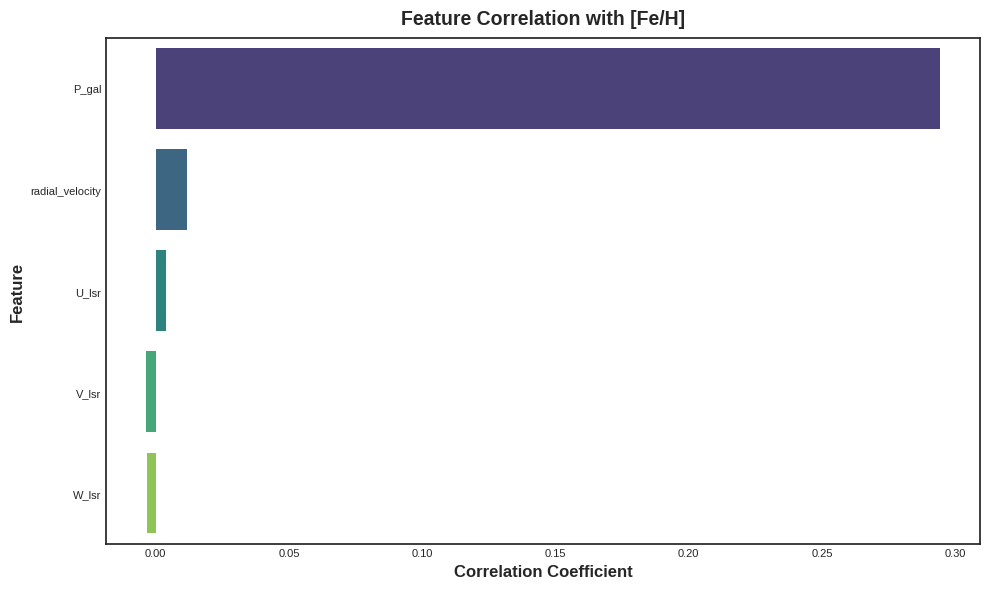

In [93]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.barplot(x=correlations.values, y=correlations.index, palette="viridis")
plt.title('Feature Correlation with [Fe/H]')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


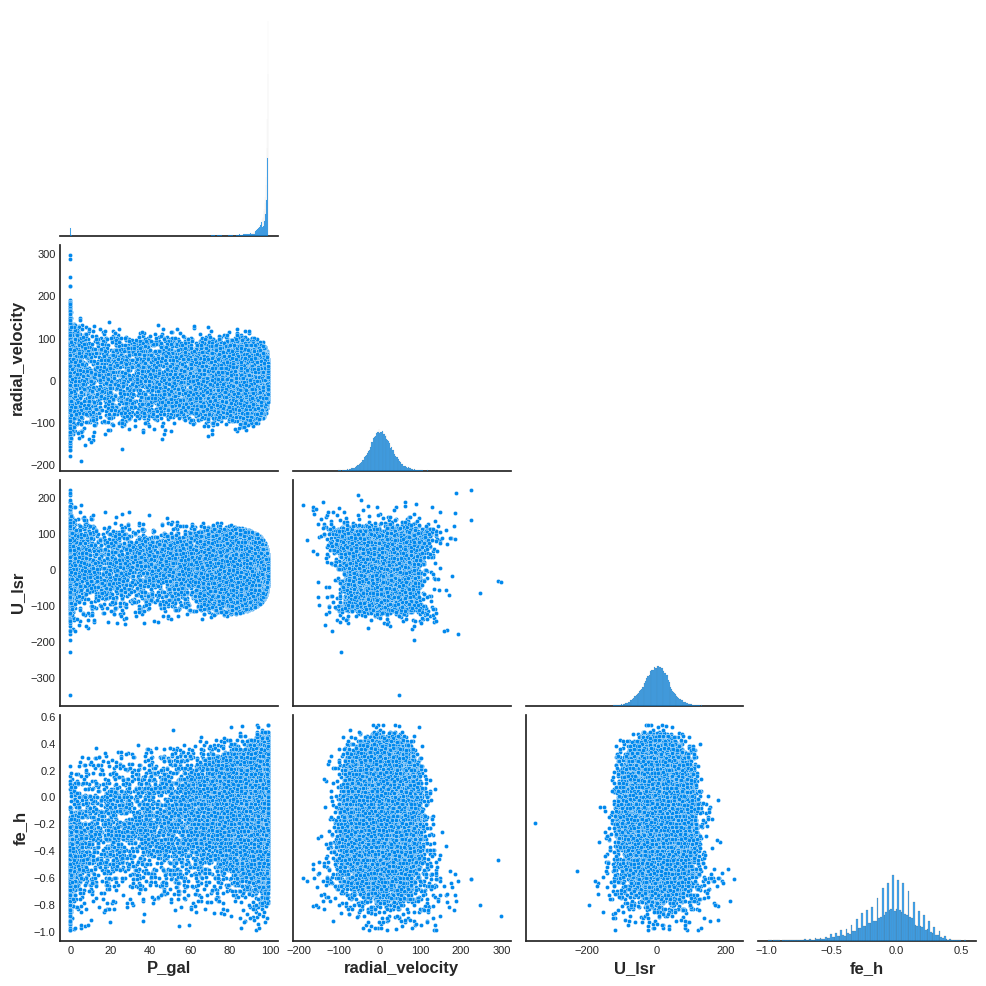

In [94]:
top_features = correlations.head(3).index.tolist()
sns.pairplot(X_combined_train.assign(fe_h=y_combined_train), vars=top_features + ['fe_h'], corner=True)


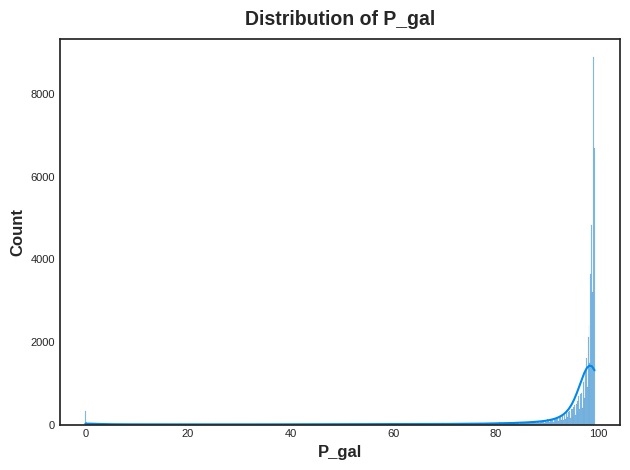

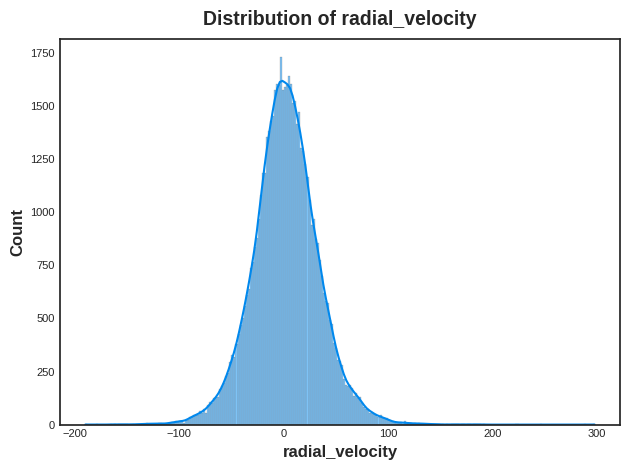

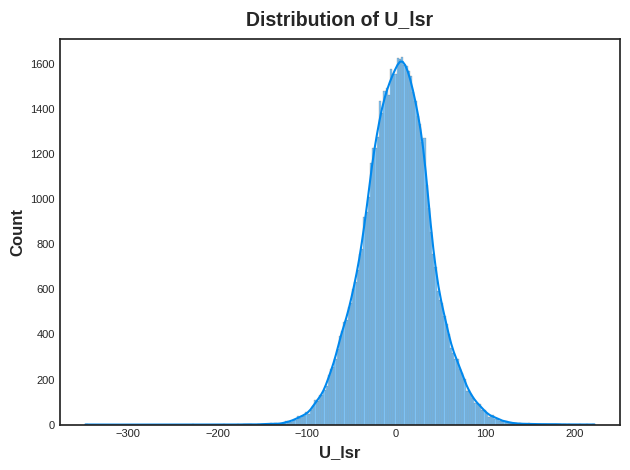

In [95]:
for col in top_features:
    sns.histplot(data=X_combined_train, x=col, kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()


pandas-profiling (now renamed to ydata-profiling)
✅ What it gives:
Target correlation heatmaps

Distribution plots of features

Missing value analysis

Duplicates detection

Interaction matrices

Report export (HTML, JSON)

In [96]:
from ydata_profiling import ProfileReport
#profile = ProfileReport(X_combined_train.assign(fe_h=y_combined_train), title="EDA Report", explorative=True)
#profile.to_file("eda_report.html")  # Opens in your browser


In [97]:
X_combined_train.assign(fe_h=y_combined_train)

,radial_velocity,V_lsr,U_lsr,W_lsr,P_gal,fe_h
0,3.07,3.060000,-23.880000,10.630000,98.9,0.06
1,40.77,-13.740000,22.430000,22.400000,97.8,0.25
2,-16.71,16.680000,-27.500000,4.730000,98.9,-0.47
3,-102.42,-37.360000,54.630000,-65.890000,3.5,-0.22
4,-4.31,-1.140000,33.440000,13.330000,98.7,-0.14
...,...,...,...,...,...,...
58543,-32.95,-6.349444,30.458417,2.100860,99.0,0.00
58544,7.97,9.435845,-16.813867,-2.171730,99.1,-0.24
58545,-19.21,-3.604424,6.957707,7.788740,99.1,0.05
58546,-40.95,4.431608,29.273100,22.313785,98.0,0.07


In [98]:
import sweetviz as sv

#report = sv.analyze([X_combined_train.assign(fe_h=y_combined_train), "Train"], target_feat="fe_h")
#report.show_html("sweetviz_report.html")


In [99]:
#sv.compare([X_combined_train.assign(fe_h=y_combined_train), "Train"], [harps, "Test"]).show_html("compare.html")


First 5 of 5 features:
P_gal              0.059908
V_lsr              0.044735
W_lsr              0.044126
U_lsr              0.020924
radial_velocity    0.014045
Name: MI Scores, dtype: float64


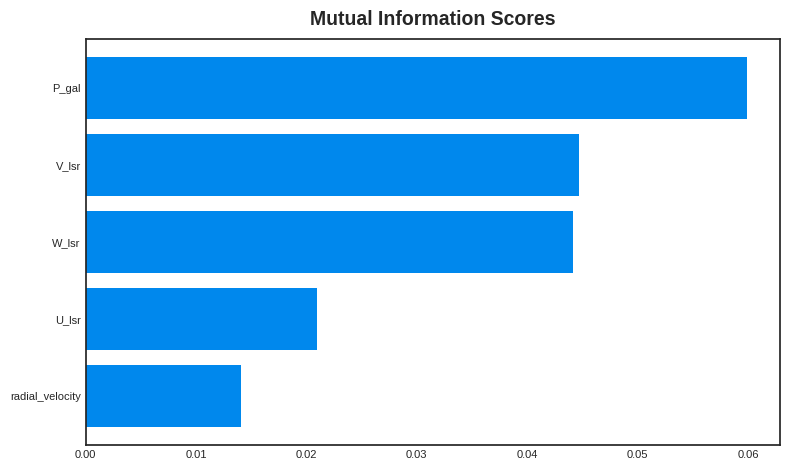

In [100]:
mi_scores = make_mi_scores(X_combined_train, y_combined_train,  plot = True)

In [101]:
X_scaled, X_test_scaled = preprocess_data(X_combined_train, X_test=None, standardize=True, factorize=False)


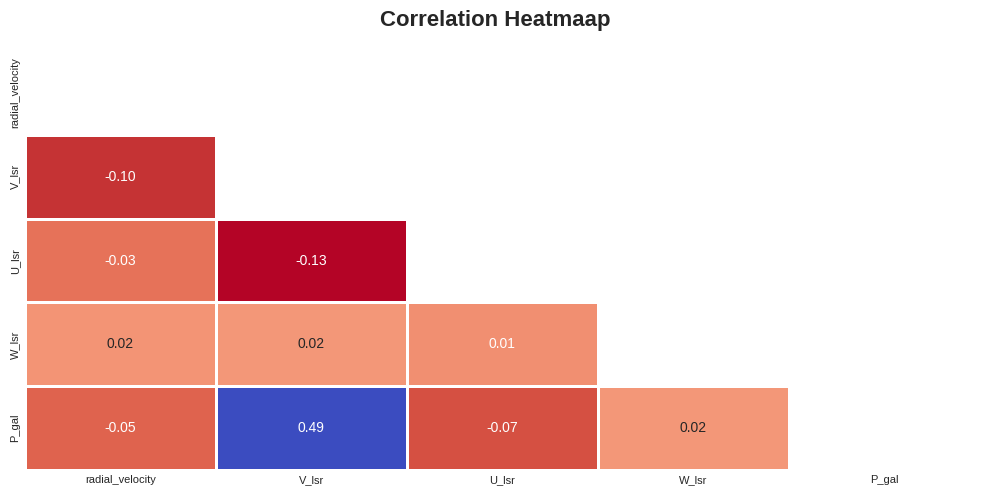

In [102]:
# Displays the correlation hitmap
corr_heatmap_plot(X_scaled)

In [103]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_new = X_combined_train.copy()
#X_new.drop(columns = ['UW_lsr', 'UVW_lsr'], inplace = True)
# Calculate VIF for each predictor variable
vif = pd.DataFrame()
vif['Variable'] = X_new.columns
vif['VIF'] = [variance_inflation_factor(X_new.values, i) for i in range(X_new.shape[1])]

print(vif[vif['VIF'] > 0])

          Variable       VIF
0  radial_velocity  1.016143
1            V_lsr  1.124321
2            U_lsr  1.018954
3            W_lsr  1.001973
4            P_gal  1.094067


In [104]:
def model_test_CV_models(X, y, models, k=5, random_state=random_state):
    """
    Perform k-fold cross-validation for multiple models and return mean MAE scores and elapsed time.

    Parameters:
        X (DataFrame): Feature matrix.
        y (Series): Target vector.
        models (dict): Dictionary of model_name: model_instance.
        k (int): Number of folds.
        random_state (int): Seed for reproducibility.

    Returns:
        dict: {model_name: {'mean_mae': ..., 'std_mae': ..., 'time_sec': ...}}
    """
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    results = {}

    for name, model in models.items():
        print(f"Scoring model: {name}")
        start_time = time.time()
        mae_scores = []

        for train_index, test_index in kf.split(X, y):
            X_train, X_test = X.iloc[train_index], X.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]

            # Special handling for scikeras models
            if isinstance(model, KerasRegressor):
                model.set_params(model__input_dim=X_train.shape[1])

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            mae = mean_absolute_error(y_test, y_pred)
            mae_scores.append(mae)

        elapsed_time = time.time() - start_time
        results[name] = {
            'mean_mae': np.mean(mae_scores),
            'std_mae': np.std(mae_scores),
            'time_sec': elapsed_time
        }

        print(f"{name} done in {elapsed_time:.2f}s → MAE: {results[name]['mean_mae']:.3f} ± {results[name]['std_mae']:.3f}\n")

    return results


In [105]:
baseline_results = model_test_CV_models(X_combined_train, y_combined_train, model_names, k=5)

for name, score in baseline_results.items():
    print(f"{name:8s} | MAE: {score['mean_mae']:.3f} ± {score['std_mae']:.3f}")


Scoring model: xgbr
xgbr done in 1.55s → MAE: 0.150 ± 0.001

Scoring model: lgbr
lgbr done in 4.25s → MAE: 0.147 ± 0.001

xgbr     | MAE: 0.150 ± 0.001
lgbr     | MAE: 0.147 ± 0.001


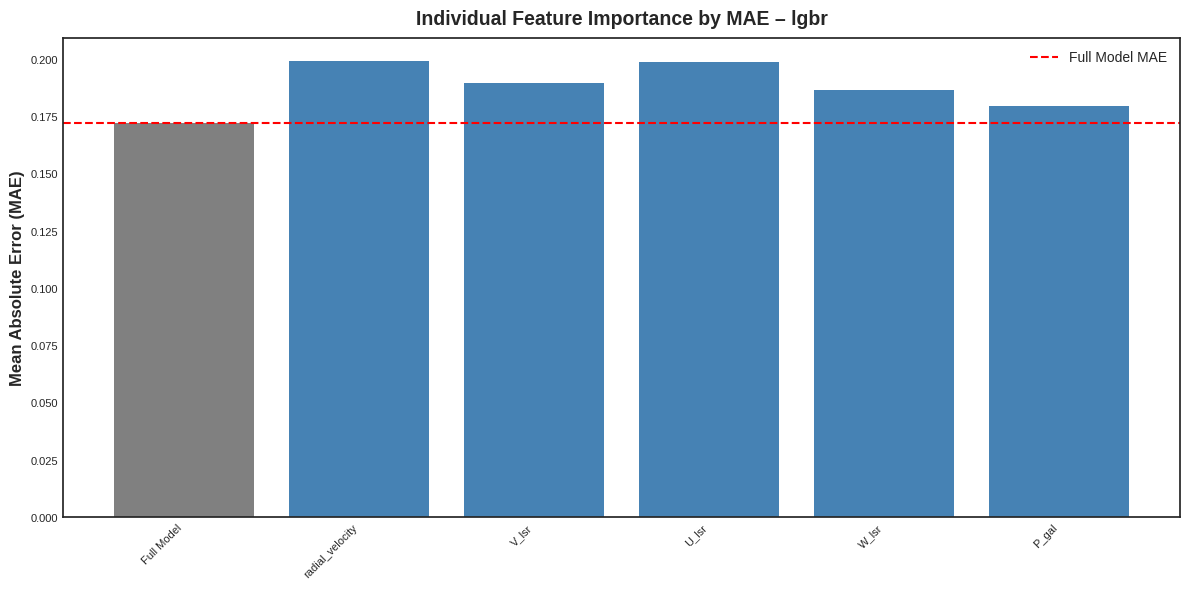

In [106]:
from sklearn.base import clone

def individual_feature_importance(model, model_name, X, y, X_test, y_test):
    """
    Trains a model with each feature individually and compares MAE to full model.
    """
    model_full = clone(model)
    model_full.fit(X, y)

    feature_names = X.columns

    # Full prediction
    y_pred_full = model_full.predict(X_test)
    mae_full = mean_absolute_error(y_test, y_pred_full)

    # Individual feature performance
    mae_individual = []
    for feature in feature_names:
        model_feat = clone(model)
        model_feat.fit(X[[feature]], y)
        y_pred_feat = model_feat.predict(X_test[[feature]])
        mae_individual.append(mean_absolute_error(y_test, y_pred_feat))

    # Plot
    plt.figure(figsize=(12, 6))
    plt.bar(['Full Model'] + list(feature_names), [mae_full] + mae_individual, color=['gray'] + ['steelblue']*len(feature_names))
    plt.axhline(y=mae_full, color='red', linestyle='--', label='Full Model MAE')

    plt.ylabel('Mean Absolute Error (MAE)')
    plt.title(f'Individual Feature Importance by MAE – {model_name}')
    plt.xticks(rotation=45, ha='right')
    plt.legend()
    plt.tight_layout()
    plt.show()


# Example for one model and one test set
best_model_name = 'lgbr'
model = model_names[best_model_name]
individual_feature_importance(model, 'lgbr', X_combined_train, y_combined_train, X_harps, y_harps)

Feature importance: ['P_gal' 'V_lsr' 'U_lsr' 'W_lsr' 'radial_velocity']


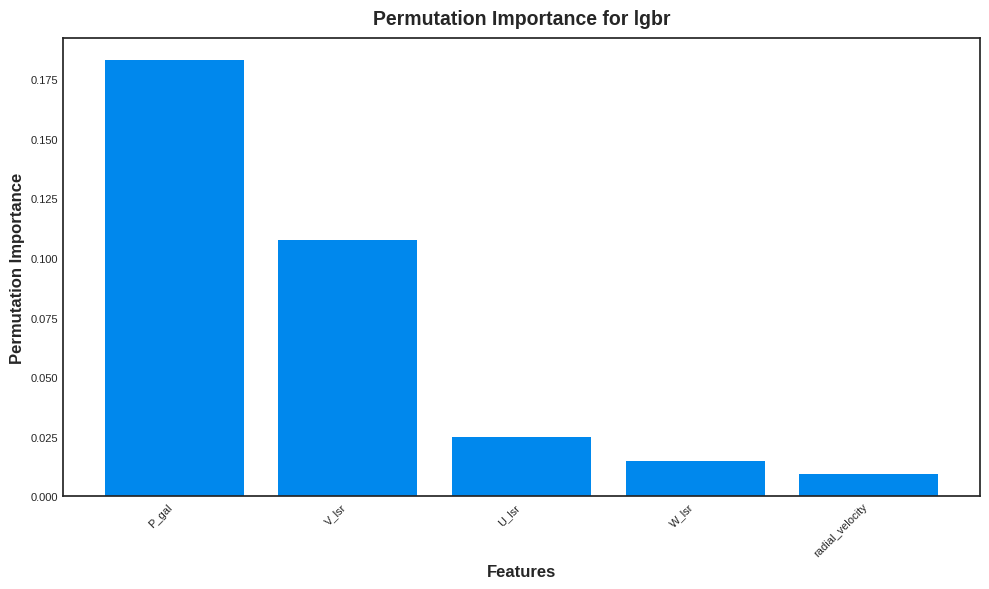

In [107]:
def feat_importance_permut(model, model_name, X, y, n_repeats = 10):
    from sklearn.inspection import permutation_importance

    X_trian, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model.fit(X_trian, y_train)
    

    # Calculate MAE on the original test set
    y_pred = model.predict(X_test)
    mae_original = mean_absolute_error(y_test, y_pred)

    # Use permutation importance to obtain feature importances
    result = permutation_importance(model, X_test, y_test, n_repeats=n_repeats, random_state=42)

    # Get feature importances and indices
    feature_importances = result.importances_mean
    sorted_indices = feature_importances.argsort()[::-1]

    print (f'Feature importance: {X.columns[sorted_indices].values}')

    # Plot the feature importances
    plt.figure(figsize=(10, 6))
    plt.bar(range(len(sorted_indices)), feature_importances[sorted_indices], tick_label=X.columns[sorted_indices])
    plt.xlabel('Features')
    plt.ylabel('Permutation Importance')
    plt.title(f'Permutation Importance for {model_name}')
    plt.xticks(rotation=45, ha='right')
    plt.show()

feat_importance_permut(model, 'lgbr', X_combined_train, y_combined_train, n_repeats = 10)

In [109]:
def ols(x, y):
    x_with_const = sm.add_constant(x)
    model = sm.OLS(y, x_with_const)
    results = model.fit()
    coeff1_ols, coeff2_ols = results.params[0], results.params[1]
    p_values = results.pvalues
    return coeff1_ols, coeff2_ols, p_values

MAE = 0.17


/tmp/ipykernel_66685/4033565634.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coeff1_ols, coeff2_ols = results.params[0], results.params[1]
/tmp/ipykernel_66685/4033565634.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coeff1_ols, coeff2_ols = results.params[0], results.params[1]
/tmp/ipykernel_66685/2144242194.py:23: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.title(f'{p_value[1]:.2f}')
/tmp/ipykernel_66685/4033565

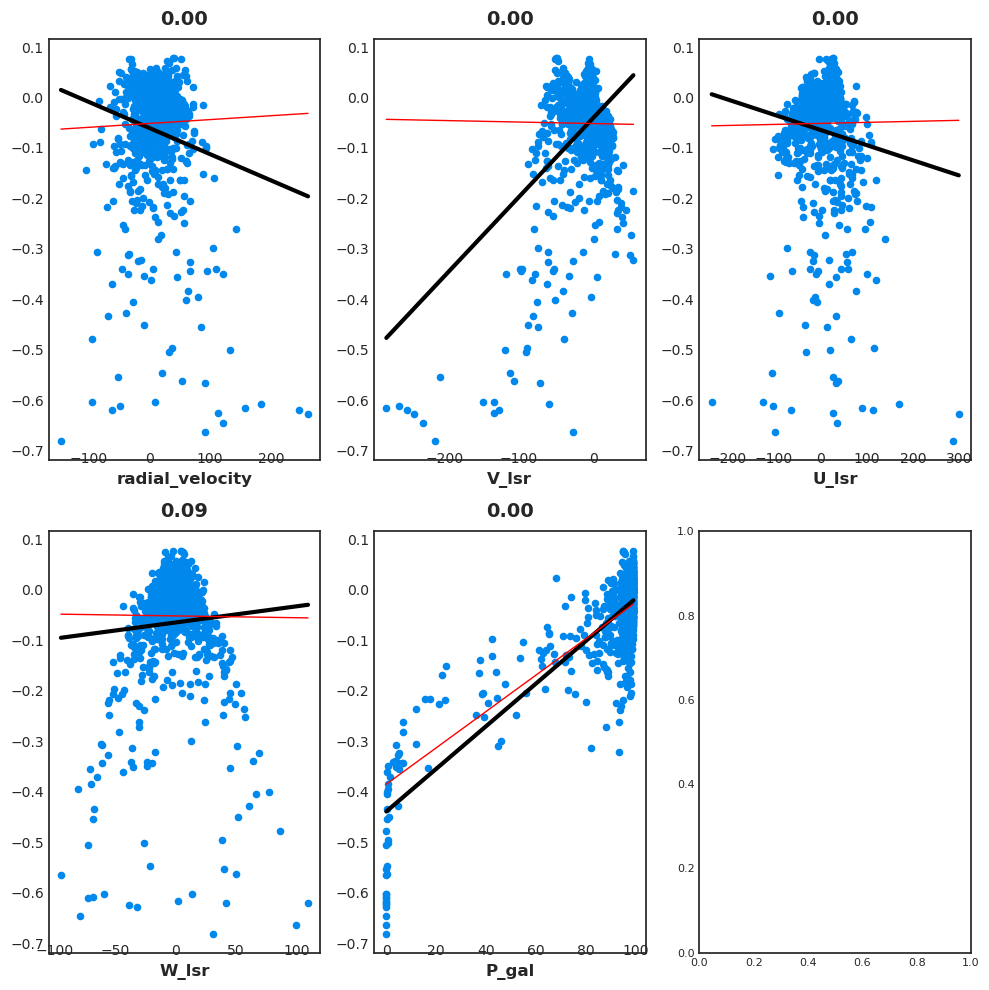

In [116]:
def dependence_on_feature_plot(model, X, y, X_test, y_test):
    model.fit(X, y)
    y_pred = model.predict(X_test)
    print (f'MAE = {mean_absolute_error(y_test, y_pred):.2f}')

    sns.set_style('white')
    fig, ax = plt.subplots(2, 3, figsize=(10, 10))

    for i, feature in enumerate(X.columns, start=1):

        coeff1_ols, coeff2_ols, p_value = ols(X_test[feature], y_pred)
        coeff1_train_ols, coeff2_train_ols, p_value_train = ols(X[feature], y)

        x_line = np.array(np.arange(np.min(X_test[feature]), np.max(X_test[feature]),0.001))
        y_line = coeff1_ols +  coeff2_ols *x_line
        y_line_train = coeff1_train_ols +  coeff2_train_ols *x_line

        plt.subplot(2, 3, i)
        plt.scatter(X_test[feature], y_pred, s = 20)
        plt.plot(x_line, y_line, color = 'black', lw = 3)
        plt.plot(x_line, y_line_train, color = 'red', lw = 1, label = 'Train')
        plt.xlabel(feature, fontsize=12)
        plt.title(f'{p_value[1]:.2f}')
        plt.tick_params(axis='x', which='major', labelsize=10, pad=-6)
        plt.tick_params(axis='y', which='major', labelsize=10)


dependence_on_feature_plot(model, X_combined_train, y_combined_train, X_harps, y_harps)